In [5]:
!pip install -q qiskit qiskit-aer matplotlib numpy scipy pylatexenc

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# ----------------------------------------------------
# 1. Define Flight Path Optimization Problem (QUBO)
# Flight decision variables: q0, q1, q2 (representing route choices/waypoints)
# ----------------------------------------------------
# Cost matrix Q penalizes conflicting airspace/long routes
Q = np.array([
    [ 2.0, -1.0,  0.5],
    [-1.0,  3.0, -1.5],
    [ 0.5, -1.5,  1.5]
])

def qubo_energy(bitstring, Q):
    """Calculates classical cost for a given bitstring choice (e.g. '101')"""
    x = np.array([int(b) for b in bitstring])
    return float(x.T @ Q @ x)

# ----------------------------------------------------
# 2. Build Parameterized QAOA Quantum Circuit
# ----------------------------------------------------
def build_qaoa_circuit(gamma, beta):
    num_qubits = Q.shape[0]
    qc = QuantumCircuit(num_qubits, num_qubits)

    # Step A: Equal Superposition (Hadamard Gates)
    for q in range(num_qubits):
        qc.h(q)

    # Step B: Problem Unitary (Cost Layer)
    for i in range(num_qubits):
        qc.rz(2 * gamma * Q[i, i], i)

    for i in range(num_qubits):
        for j in range(i + 1, num_qubits):
            if Q[i, j] != 0:
                qc.cx(i, j)
                qc.rz(2 * gamma * Q[i, j], j)
                qc.cx(i, j)

    # Step C: Mixer Unitary (Mixer Layer)
    for q in range(num_qubits):
        qc.rx(2 * beta, q)

    # Step D: Measurement
    qc.measure(range(num_qubits), range(num_qubits))
    return qc

# ----------------------------------------------------
# 3. Simulation & Optimization Loop
# ----------------------------------------------------
simulator = AerSimulator()
cost_history = []

def objective_function(params):
    gamma, beta = params
    qc = build_qaoa_circuit(gamma, beta)

    # Run simulation with 1024 shots
    result = simulator.run(qc, shots=1024).result()
    counts = result.get_counts()

    # Calculate expectation value (average energy)
    total_energy = 0
    shots = sum(counts.values())
    for bitstring, count in counts.items():
        # Reverse string to match Qiskit qubit ordering (q0 on right)
        reversed_bitstring = bitstring[::-1]
        energy = qubo_energy(reversed_bitstring, Q)
        total_energy += energy * count

    avg_energy = total_energy / shots
    cost_history.append(avg_energy)
    return avg_energy

# Run Optimization using COBYLA
initial_params = [0.5, 0.5]
res = minimize(objective_function, initial_params, method='COBYLA')

print("Optimization Complete!")
print("Optimal Gamma:", res.x[0])
print("Optimal Beta:", res.x[1])
print("Minimum Energy Reached:", res.fun)

Optimization Complete!
Optimal Gamma: 0.2818618737471368
Optimal Beta: 0.9631426632522531
Minimum Energy Reached: 0.72998046875


--- 1. QAOA Quantum Circuit ---
Could not render circuit with 'mpl' (Matplotlib). Falling back to text representation:



┌───┐ ┌────────────┐                                                   »
q_0: ┤ H ├─┤ Rz(1.1274) ├──■────────────────────■────■───────────────────■──»
     ├───┤ ├────────────┤┌─┴─┐┌──────────────┐┌─┴─┐  │                   │  »
q_1: ┤ H ├─┤ Rz(1.6912) ├┤ X ├┤ Rz(-0.56372) ├┤ X ├──┼───────────────────┼──»
     ├───┤┌┴────────────┤└───┘└──────────────┘└───┘┌─┴─┐┌─────────────┐┌─┴─┐»
q_2: ┤ H ├┤ Rz(0.84559) ├──────────────────────────┤ X ├┤ Rz(0.28186) ├┤ X ├»
     └───┘└─────────────┘                          └───┘└─────────────┘└───┘»
c: 3/═══════════════════════════════════════════════════════════════════════»
                                                                            »
«     ┌────────────┐                ┌─┐                         
«q_0: ┤ Rx(1.9263) ├────────────────┤M├─────────────────────────
«     └────────────┘                └╥┘     ┌────────────┐┌─┐   
«q_1: ──────■────────────────────────╫───■──┤ Rx(1.9263) ├┤M├───
«         ┌─┴─┐     ┌──────────────┐ ║ ┌─┴─┐├────────────┤└╥┘┌─┐
«q_2: ────┤ X ├─────┤ Rz(-0.84559) ├─╫─┤ X ├┤ Rx(1.9263) ├─╫─┤M├
«         └───┘     └──────────────┘ ║ └───┘└────────────┘ ║ └╥┘
«c: 3/═══════════════════════════════╩═════════════════════╩══╩═
«                                    0                     1  2

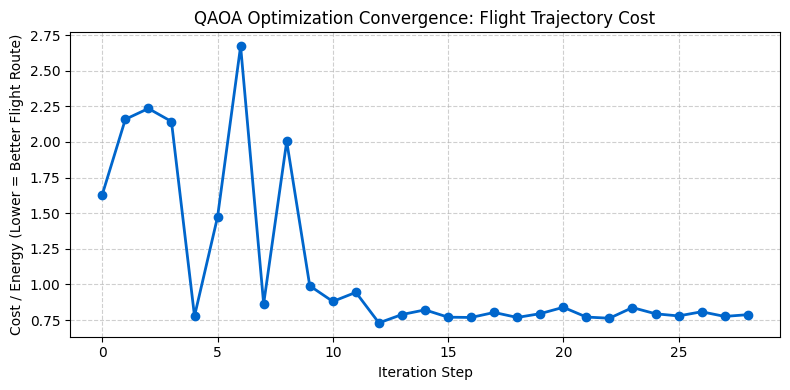

--- 2. Final Route Solution Measurement ---


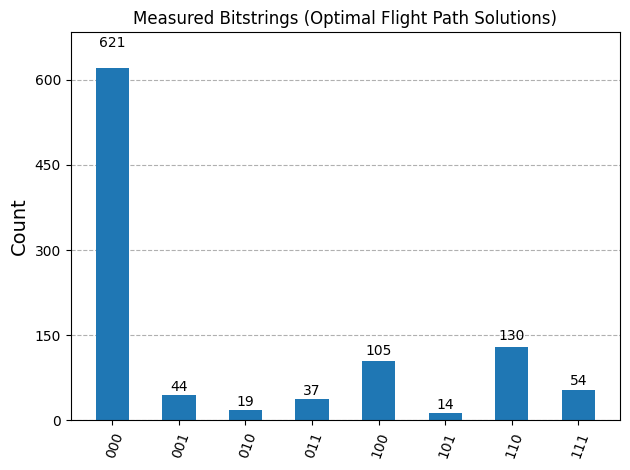


✈️ Optimal Decoded Flight Trajectory Choice: Bitstring '000'


In [8]:
# 1. Quantum Circuit Diagram
optimal_qc = build_qaoa_circuit(res.x[0], res.x[1])
print("--- 1. QAOA Quantum Circuit ---")
try:
    display(optimal_qc.draw('mpl'))
except Exception as e:
    print("Could not render circuit with 'mpl' (Matplotlib). Falling back to text representation:\n")
    display(optimal_qc.draw('text'))

# 2. Optimization Cost Curve (Convergence)
plt.figure(figsize=(8, 4))
plt.plot(cost_history, marker='o', color='#0066CC', linewidth=2)
plt.title("QAOA Optimization Convergence: Flight Trajectory Cost")
plt.xlabel("Iteration Step")
plt.ylabel("Cost / Energy (Lower = Better Flight Route)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 3. Final Probability Distribution Histogram
result = simulator.run(optimal_qc, shots=1024).result()
counts = result.get_counts()

print("--- 2. Final Route Solution Measurement ---")
display(plot_histogram(counts, title="Measured Bitstrings (Optimal Flight Path Solutions)"))

# Decoded Best Trajectory
best_bitstring = max(counts, key=counts.get)[::-1]
print(f"\n✈️ Optimal Decoded Flight Trajectory Choice: Bitstring '{best_bitstring}'")